# 02 · Image Preprocessing

**Goal:** turn the raw MRI images into clean inputs of identical shape that a neural network can learn from, and prepare the train / validation / test split.

Steps: resize → normalize → encode labels → split (after removing duplicates) → augmentation demo.

In [1]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import tensorflow as tf

In [2]:
DATASET_DIR = Path("../dataset")

TRAIN_DIR = DATASET_DIR / "Training"
TEST_DIR = DATASET_DIR / "Testing"
IMAGES_DIR = Path("../images")

print("Training directory exists:", TRAIN_DIR.exists())
print("Testing directory exists:", TEST_DIR.exists())

Training directory exists: True
Testing directory exists: True


## 1 Image Resizing

Target image dimensions: 224 × 224 pixels.

**Why resize?** A neural network needs every input to have exactly the same shape. Notebook 01 showed our images come in many sizes, so we resize all of them to 224 x 224: large enough to keep the tumor detail, small enough to train quickly.

**Why grayscale?** An MRI scan has no real colour, and notebook 01 showed mixed colour modes (L / RGB / RGBA / P). The later notebooks therefore load every image as 1 channel (`channels=1` / `color_mode="grayscale"`).

**Note:** this demo uses PIL (LANCZOS). The training notebooks use `tf.image.resize`. The deployed app must resize the same way the model was trained.

In [3]:
# Target image dimensions
IMG_SIZE = (224, 224)
print("Target image size:", IMG_SIZE)

Target image size: (224, 224)


In [4]:
#select one mri image from training data 
image_extensions = {".jpg", ".jpeg", ".png"}

training_images = [path for path in TRAIN_DIR.rglob("*") if path.suffix.lower() in image_extensions]

sample_path = random.choice(training_images) 
original_img = Image.open(sample_path) 

print("Image path:", sample_path)
print("Original dimensions:", original_img.size)
print("Original image mode:", original_img.mode)

Image path: ..\dataset\Training\notumor\Tr-no_534.jpg
Original dimensions: (235, 229)
Original image mode: RGB


In [5]:
# Resize MRI image
resized_img = original_img.resize(IMG_SIZE,Image.Resampling.LANCZOS)

print("Original dimensions:", original_img.size)
print("Resized dimensions:", resized_img.size)

Original dimensions: (235, 229)
Resized dimensions: (224, 224)


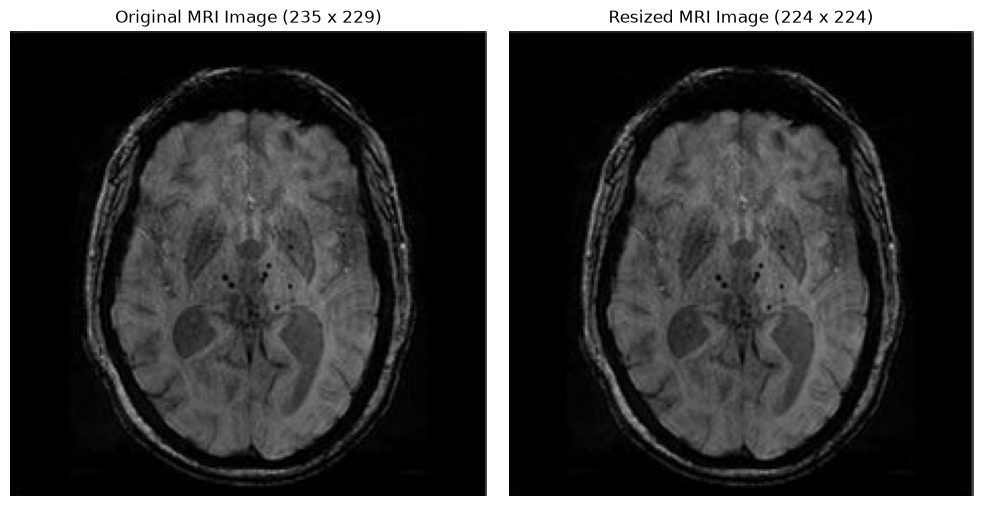

In [6]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_img, cmap="gray")
plt.title(f"Original MRI Image ({original_img.size[0]} x {original_img.size[1]})")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_img, cmap="gray")
plt.title("Resized MRI Image (224 x 224)")
plt.axis("off")

plt.tight_layout()
plt.savefig(IMAGES_DIR / "02_resize_example.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
print("Original size:", original_img.size)
print("Resized size:", resized_img.size)

print("Original image type:", type(original_img)) 
print("Resized image type:", type(resized_img)) 

Original size: (235, 229)
Resized size: (224, 224)
Original image type: <class 'PIL.JpegImagePlugin.JpegImageFile'>
Resized image type: <class 'PIL.Image.Image'>


## 2  Image Normalization

In [8]:
# Convert resized image into NumPy array
image_array = np.array(resized_img)

print("Array shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())

Array shape: (224, 224, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 194


In [9]:
# Normalize pixel values from 0-255 to 0-1
normalized_img = image_array.astype("float32") / 255.0

print("Normalized data type:", normalized_img.dtype)
print("Minimum normalized value:", normalized_img.min())
print("Maximum normalized value:", normalized_img.max())

Normalized data type: float32
Minimum normalized value: 0.0
Maximum normalized value: 0.7607843


## 3 Class labels

A neural network cannot use words like "glioma", it needs numbers. We sort the class names alphabetically and give each one an index: glioma = 0, meningioma = 1, notumor = 2, pituitary = 3.
This order must be the same in the app, otherwise predictions would be shown with the wrong names.

In [10]:
# Get class names from training folders
class_names = sorted([folder.name for folder in TRAIN_DIR.iterdir() if folder.is_dir()])

print("Class names:", class_names)
print("Total classes:", len(class_names))

Class names: ['glioma', 'meningioma', 'notumor', 'pituitary']
Total classes: 4


In [11]:
# Convert class names into numerical labels
class_to_label = {class_name: index for index, class_name in enumerate(class_names)}
print("Class to label mapping:")

for class_name, label in class_to_label.items():
    print(f"{class_name} - {label}")

Class to label mapping:
glioma - 0
meningioma - 1
notumor - 2
pituitary - 3


In [12]:
# Collect image paths
image_extensions = {".jpg", ".jpeg", ".png"}

train_paths = sorted([path for path in TRAIN_DIR.rglob("*") if (path.suffix.lower() in image_extensions)])
test_paths = sorted([path for path in TEST_DIR.rglob("*") if (path.suffix.lower() in image_extensions)])

# Encode labels
train_labels = np.array([class_to_label[path.parent.name] for path in train_paths])
test_labels = np.array([class_to_label[path.parent.name] for path in test_paths])

print("Training labels shape:", train_labels.shape)
print("Testing labels shape:", test_labels.shape)

print("First 10 training labels:", train_labels[:10])

Training labels shape: (5600,)
Testing labels shape: (1600,)
First 10 training labels: [0 0 0 0 0 0 0 0 0 0]


In [13]:
# Collect image paths
image_extensions = {".jpg", ".jpeg", ".png"}

train_paths = sorted([path for path in TRAIN_DIR.rglob("*") if (path.suffix.lower() in image_extensions)])
test_paths = sorted([path for path in TEST_DIR.rglob("*") if (path.suffix.lower() in image_extensions)])

# Encode labels
train_labels = np.array([class_to_label[path.parent.name] for path in train_paths])
test_labels = np.array([class_to_label[path.parent.name] for path in test_paths])

print("Training labels shape:", train_labels.shape)
print("Testing labels shape:", test_labels.shape)

print("First 10 training labels:", train_labels[:10])

Training labels shape: (5600,)
Testing labels shape: (1600,)
First 10 training labels: [0 0 0 0 0 0 0 0 0 0]


## 4  Train, Validation and Test Splitting

**Three sets, three jobs:** *Training* = the model learns from it. *Validation* = we watch it during training to spot overfitting and compare settings. *Test* = the final exam, used only at the end.
We split the original Training folder 80 / 20 into train and validation, and keep the Testing folder untouched. `stratify` keeps the class proportions equal in both parts.

**Duplicates first:** notebook 01 found repeated copies of some images. If one copy lands in train and its twin in validation, the model is graded on an image it has already seen, and validation accuracy looks better than it really is. So we remove duplicate copies from the Training images **before** splitting. The Testing folder is left as it is.

**Note:** the path-overlap check further below only proves that no *file* is in two sets, not that no *image content* is.

In [14]:
import hashlib

def file_hash(path):
    return hashlib.md5(path.read_bytes()).hexdigest()

seen, keep = set(), []
for i, path in enumerate(train_paths):
    h = file_hash(path)
    if h not in seen:          # keep only the first copy of each image
        seen.add(h)
        keep.append(i)

print("Training images before removing duplicates:", len(train_paths))
train_paths = [train_paths[i] for i in keep]
train_labels = train_labels[keep]
print("Training images after removing duplicates: ", len(train_paths))

Training images before removing duplicates: 5600
Training images after removing duplicates:  5429


In [15]:
from sklearn.model_selection import train_test_split

# Spliting existing training data into training and validation
X_train, X_val, y_train, y_val = train_test_split(train_paths,train_labels,test_size=0.2,random_state=42,stratify=train_labels)

# Keeping original testing data separate
X_test = test_paths 
y_test = test_labels

In [16]:
print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))
print("Total images:",len(X_train) + len(X_val) + len(X_test))

Training images: 4343
Validation images: 1086
Testing images: 1600
Total images: 7029


In [17]:
for class_name, label in class_to_label.items():
    train_count = np.sum(y_train == label)
    val_count = np.sum(y_val == label)
    test_count = np.sum(y_test == label)
    print(f"{class_name}: Train={train_count}, Validation={val_count}, Test={test_count}")

glioma: Train=1120, Validation=280, Test=400
meningioma: Train=1109, Validation=277, Test=400
notumor: Train=1025, Validation=256, Test=400
pituitary: Train=1089, Validation=273, Test=400


## 5 Data Augmentation

In [18]:
from tensorflow.keras import layers

# Select one training image
augmentation_sample_path = X_train[0]

# Load and resize image
sample_image = tf.keras.utils.load_img(augmentation_sample_path,target_size=IMG_SIZE,color_mode="grayscale")

# Convert image into NumPy array 
sample_array = tf.keras.utils.img_to_array(sample_image)

# Normalize pixel values
sample_array = sample_array / 255.0

# Add batch dimension
sample_batch = tf.expand_dims(sample_array, axis=0)

print("Image shape:", sample_array.shape)
print("Batch shape:", sample_batch.shape)
print("Minimum pixel:", sample_array.min())
print("Maximum pixel:", sample_array.max())

Image shape: (224, 224, 1)
Batch shape: (1, 224, 224, 1)
Minimum pixel: 0.043137256
Maximum pixel: 1.0


In [19]:
data_augmentation = tf.keras.Sequential([layers.RandomRotation(factor=0.05,fill_mode="nearest"),
                                         layers.RandomTranslation(height_factor=0.05,width_factor=0.05,fill_mode="nearest"),
                                         layers.RandomZoom(height_factor=0.10,width_factor=0.10,fill_mode="nearest")])

augmented_batch = data_augmentation(sample_batch,training=True) 
augmented_image = augmented_batch[0].numpy() 

print("Original shape:", sample_array.shape) 
print("Augmented shape:", augmented_image.shape) 

Original shape: (224, 224, 1)
Augmented shape: (224, 224, 1)


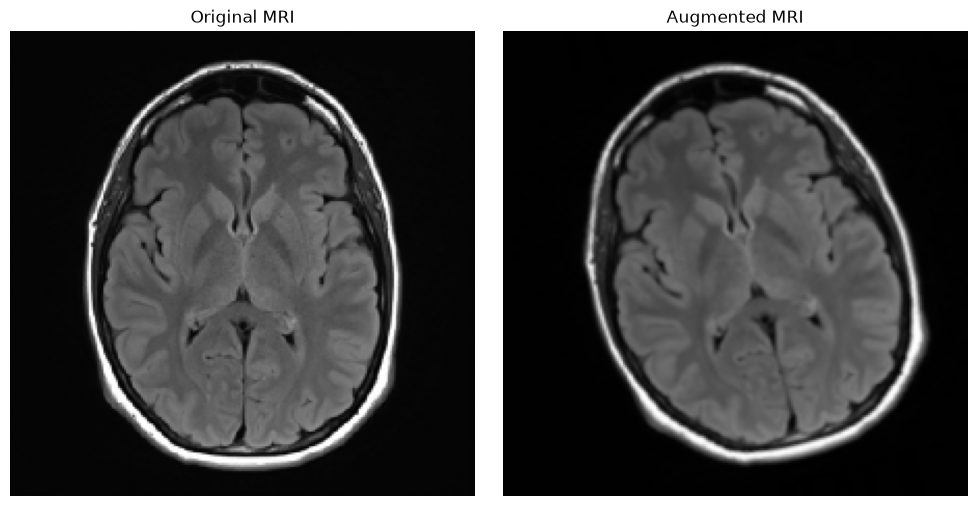

In [20]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(sample_array.squeeze(), cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(augmented_image.squeeze(), cmap="gray")
plt.title("Augmented MRI")
plt.axis("off")

plt.tight_layout()
plt.savefig(IMAGES_DIR / "02_augmentation_example.png", dpi=200, bbox_inches="tight")
plt.show()

## Summary and decisions

| Step | Decision |
|---|---|
| Resize | All images to 224 x 224 |
| Colour | 1-channel grayscale |
| Normalize | Divide pixel values by 255 (range 0 to 1) |
| Labels | Alphabetical: glioma 0, meningioma 1, notumor 2, pituitary 3 |
| Split | 80 / 20 train / validation from the Training folder (duplicates removed first, stratified, `random_state=42`); Testing folder untouched |
| Augmentation | Rotation 5%, shift 5%, zoom 10% (training only; not used by the models yet) |


**Next:** `03_ann_model.ipynb`